In [1]:
import SimpleITK as sitk
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt


In [2]:
output_dir = Path("/workspaces/segmentation/data/output")

In [3]:
def get_cut_parameter ( c1_dir, c7_dir, t12_dir):
    
    c1_mask = sitk.ReadImage(c1_dir)
    c7_mask = sitk.ReadImage(c7_dir)
    t12_mask = sitk.ReadImage(t12_dir)
    
    masks = {"c1": c1_mask, "c7": c7_mask, "t12": t12_mask}
    cut_parameter = {}
    
    for name, mask in masks.items():
        stats = sitk.LabelShapeStatisticsImageFilter()
        stats.Execute(mask)
        _, _, z_start, _, _, z_size = stats.GetBoundingBox(1)
        cut_parameter[name] = {"z_start": z_start, "z_size": z_size}

    carnial_top_cut = cut_parameter["c1"]["z_start"] + cut_parameter["c1"]["z_size"] # make volex start from c1 0
    carnial_bottom_cut = cut_parameter["c7"]["z_start"] # make voxel before c7 0
    thoracic_top_cut = cut_parameter["c7"]["z_start"] # make voxel start from c7 0
    thoracic_bottom_cut = cut_parameter["t12"]["z_start"] #make voxel before t12 0
    return  carnial_top_cut, carnial_bottom_cut, thoracic_top_cut, thoracic_bottom_cut
    


In [ ]:
for subject_dir in sorted(output_dir.iterdir()): #iterate through all subjects
        if subject_dir.is_dir():   
            subject_name = subject_dir.name
            
            for session_dir in sorted(subject_dir.iterdir()): #iterate thorugh all sessions
                if not session_dir.is_dir():
                    continue

                #get the masks dir
                spinal_cord_dir = session_dir / "spinal_cord.nii.gz"
                c1_dir = session_dir / "vertebrae_C1.nii.gz"
                c7_dir = session_dir / "vertebrae_C7.nii.gz"
                t12_dir = session_dir / "vertebrae_T12.nii.gz"

                #check if the maks exist
                if not spinal_cord_dir.is_file():
                    raise RuntimeError(f"missing spinal cord mask in {session_dir}")
                if not c1_dir.is_file():
                    raise RuntimeError(f"missing c1 spine mask in  {session_dir}")
                if not c7_dir.is_file():
                    raise RuntimeError(f"missing c7 spine mask in {session_dir}")
                if not t12_dir.is_file():
                    raise RuntimeError(f"missing t12 spine mask in {session_dir}")

                # get the cutting parameter to derive the carnial and thoracic spinal cord
                carnial_top_cut, carnial_bottom_cut, thoracic_top_cut, thoracic_bottom_cut = get_cut_parameter (c1_dir, c7_dir, t12_dir)

                #copying the spinal cord mask
                spinal_cord = sitk.ReadImage(spinal_cord_dir)
                carnial_spinal_cord = sitk.Image(spinal_cord)
                thoracic_spinal_cord = sitk.Image(spinal_cord)

                #removing maks outside the selected region
                carnial_spinal_cord[:,:,carnial_top_cut:] = 0
                carnial_spinal_cord[:,:,:carnial_bottom_cut] = 0

                thoracic_spinal_cord[:,:,thoracic_top_cut:] = 0
                thoracic_spinal_cord[:,:,:thoracic_bottom_cut] = 0

                carnial_output_dir = session_dir / "carnial_spinal_cord.nii.gz"
                thoracic_output_dir = session_dir / "thoracic_spinal_cord.nii.gz"

                # create the new masks
                sitk.WriteImage(carnial_spinal_cord, carnial_output_dir)
                sitk.WriteImage(thoracic_spinal_cord, thoracic_output_dir)
                
                print (f"Carnial and thoracic spinal cord for: {subject_name} - {session_dir.name} successfully created")

                #delete the spinal cord masks
                spinal_cord_dir.unlink()
                print(f"The spinal cord for: {subject_name} - {session_dir.name} successfully deleted")


Carnial and thoracic spinal cord for: QUADRA_HC_021 - retest successfully created
The spinal cord for: QUADRA_HC_021 - retest successfully deleted
Carnial and thoracic spinal cord for: QUADRA_HC_021 - test successfully created
The spinal cord for: QUADRA_HC_021 - test successfully deleted


In [ ]:
def show_overlay (img, mask):
    py_img = sitk.GetArrayFromImage(img)
    py_mask = sitk.GetArrayFromImage(mask)

    visible_mask = np.ma.masked_where(py_mask == 0, py_mask)

    plt.imshow(py_img, cmap="gray")
    plt.imshow(visible_mask, cmap="autumn", alpha=0.5, vmin=0, vmax=1)
    plt.axis("off")
    plt.show()


In [ ]:
img_path = Path("/workspaces/segmentation/data/input/QUADRA_HC_021/retest_CT-AC.nii.gz")

img = sitk.ReadImage(img_path)

In [4]:
sp_cord_path = Path("/workspaces/segmentation/data/output/QUADRA_HC_021/retest/spinal_cord.nii.gz")
carnial_sp_cord_path = Path("/workspaces/segmentation/data/output/QUADRA_HC_021/retest/carnial_spinal_cord.nii.gz")
thoracic_sp_cord_path = Path("/workspaces/segmentation/data/output/QUADRA_HC_021/retest/thoracic_spinal_cord.nii.gz")


sp_cord = sitk.ReadImage(sp_cord_path)
carnial_sp_cord = sitk.ReadImage(carnial_sp_cord_path)
thoracic_sp_cord = sitk.ReadImage(thoracic_sp_cord_path)


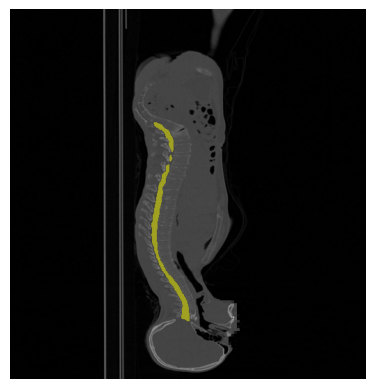

In [5]:
show_overlay(img[263,:,:],sp_cord[263,:,:])

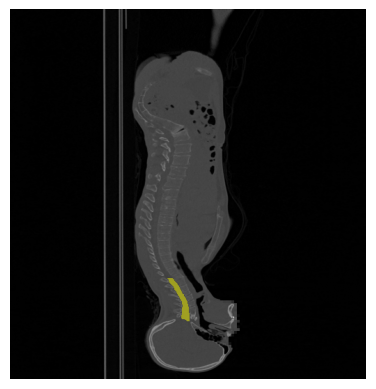

In [6]:
show_overlay(img[263,:,:],carnial_sp_cord[263,:,:])

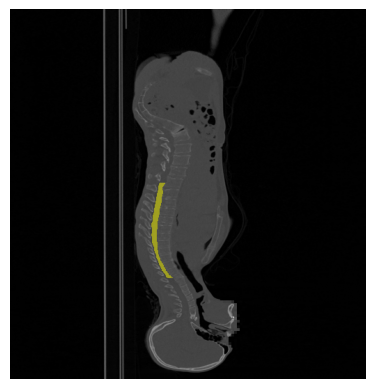

In [7]:
show_overlay(img[263,:,:],thoracic_sp_cord[263,:,:])

In [ ]:
spinal_cord_trimed = sitk.Image(sp_cord)

spinal_cord_trimed[:,:,:bottom_cut] = 0
spinal_cord_trimed[:,:,top_cut:] = 0

In [8]:
def get_properties (img):

    img_data = {
        "img_dimension" : img.GetDimension(),
        "img_size" : img.GetSize(),
        "img_orign" : img.GetOrigin(),
        "img_spacing" : img.GetSpacing(),
        "img_direction" : img.GetDirection(),
    }

    return img_data
    

In [9]:
get_properties(sp_cord)

{'img_dimension': 3,
 'img_size': (512, 512, 531),
 'img_orign': (-389.23828125, 247.73828125, 317.5),
 'img_spacing': (1.5234375, 1.5234375, 2.0),
 'img_direction': (1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)}

In [10]:
get_properties(carnial_sp_cord)

{'img_dimension': 3,
 'img_size': (512, 512, 531),
 'img_orign': (-389.23828125, 247.73828125, 317.5),
 'img_spacing': (1.5234375, 1.5234375, 2.0),
 'img_direction': (1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)}

In [11]:
get_properties(thoracic_sp_cord)

{'img_dimension': 3,
 'img_size': (512, 512, 531),
 'img_orign': (-389.23828125, 247.73828125, 317.5),
 'img_spacing': (1.5234375, 1.5234375, 2.0),
 'img_direction': (1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)}